In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Classes:", data.target_names)
print("Class counts:", np.bincount(y))

Dataset shape: (569, 30)
Target shape: (569,)
Classes: ['malignant' 'benign']
Class counts: [212 357]


In [2]:
# split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y # keeps the class proportions approximately consistent in both sets
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


In [3]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training mean of first feature:", X_train[:, 0].mean())
print("Training standard deviation:", X_train[:, 0].std())

Training mean of first feature: -4.337433952909183e-15
Training standard deviation: 1.0


In [4]:
import numpy as np
import matplotlib.pyplot as plt


class LinearSVMScratch:

    def __init__(self, learning_rate=0.01, epochs=3000, C=1.0):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.C = C
        self.w = None
        self.b = 0.0
        self.losses = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Convert labels: 0 -> -1, 1 -> +1
        y_signed = np.where(y == 0, -1.0, 1.0)

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.losses = []

        for epoch in range(self.epochs):
            # Calculate scores and margins
            scores = X @ self.w + self.b
            margins = y_signed * scores

            # Hinge loss
            hinge_losses = np.maximum(0, 1 - margins)

            # Objective: regularization + average hinge loss
            loss = (
                0.5 * np.dot(self.w, self.w)
                + self.C * np.mean(hinge_losses)
            )
            self.losses.append(loss)

            # Samples violating the margin
            active = margins < 1

            # Gradients
            dw = self.w.copy()
            db = 0.0

            if np.any(active):
                dw -= (
                    self.C / n_samples
                ) * (X[active].T @ y_signed[active])

                db = -self.C * np.mean(y_signed[active])

            # Update parameters
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return (scores >= 0).astype(int)

In [5]:
svm_model = LinearSVMScratch(
    learning_rate=0.01,
    epochs=3000,
    C=1.0
)

svm_model.fit(X_train, y_train)

svm_predictions = svm_model.predict(X_test)

accuracy = np.mean(svm_predictions == y_test)

print("First 20 predictions:", svm_predictions[:20])
print("First 20 actual labels:", y_test[:20])
print(f"Linear SVM Accuracy: {accuracy:.4f}")

First 20 predictions: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1]
First 20 actual labels: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1]
Linear SVM Accuracy: 0.9561


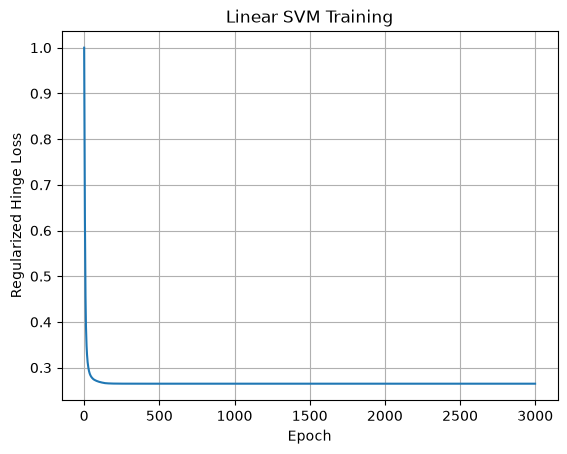

In [6]:
plt.plot(svm_model.losses)
plt.xlabel("Epoch")
plt.ylabel("Regularized Hinge Loss")
plt.title("Linear SVM Training")
plt.grid(True)
plt.show()